Bibliotecas importadas com sucesso. Ambiente Google Colab pronto.
Arquivos .parquet encontrados! Iniciando a conversão local...
Sucesso! Arquivos CSV gerados:
- indicadores_violencia_domestica_sc.csv
- dados_feminicidio.csv
Dados carregados:
Violência:    (483200, 9)
Feminicídio:  (362, 23)
População:    (295, 5)

Tipos encontrados em 'fato_comunicado':
fato_comunicado
Ameaça                                         224328
Lesão corporal leve - Dolosa                   114174
Injúria                                         73526
Vias de fato                                    31095
Difamação                                       21301
Calúnia                                         10721
Estupro                                          4186
Lesão corporal grave ou gravíssima - Dolosa      2142
Injúria qualificada pelo preconceito              966
Injúria real                                      399
Feminicídio                                       362
Name: count, dtype: int64

Registr

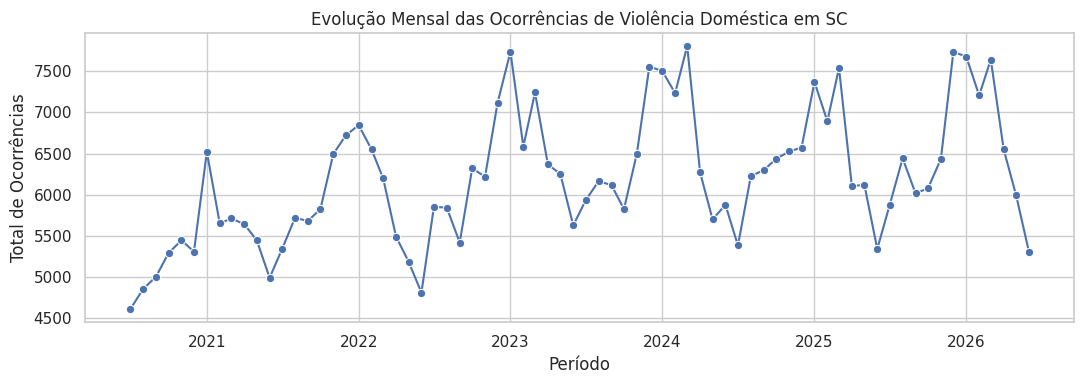


DIVISÃO TEMPORAL (SEM DATA LEAKAGE)
Data de corte: 2024-09-01
Treino: 14,750 linhas (2020-07-01 a 2024-08-01)
Teste:  6,490 linhas (2024-09-01 a 2026-06-01)

================ BENCHMARK v1 vs v2 (SPLIT TEMPORAL) ================
                          modelo  acuracia  precisao  recall  f1_score  roc_auc
 v1_Regressao_Logistica_Baseline    0.5510    0.0000  0.0000    0.0000   0.5101
       v1_Random_Forest_Baseline    0.6639    0.6450  0.5594    0.5992   0.7090
v2_Regressao_Logistica_Integrada    0.7022    0.6755  0.6479    0.6614   0.7641
         v2_Random_Forest_Tunado    0.7106    0.6710  0.6977    0.6841   0.7788
  v2_Gradient_Boosting_Integrado    0.7157    0.6919  0.6613    0.6763   0.7863

Relatório detalhado — v2 Random Forest Tunado:
              precision    recall  f1-score   support

           0       0.75      0.72      0.73      3576
           1       0.67      0.70      0.68      2914

    accuracy                           0.71      6490
   macro avg       0.71  

In [ ]:
!pip install -q pandas matplotlib seaborn scikit-learn joblib openpyxl pyarrow

import json
import os
import unicodedata
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.preprocessing import LabelEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Bibliotecas importadas com sucesso. Ambiente Google Colab pronto.")

# ============================================================
# 0. CONVERSÃO PARQUET -> CSV (SE OS ARQUIVOS PARQUET EXISTIREM)
# ============================================================
if os.path.exists("geral.parquet") and os.path.exists("feminicidio.parquet"):
    print("Arquivos .parquet encontrados! Iniciando a conversão local...")

    df_geral_raw = pd.read_parquet("geral.parquet")
    df_feminicidio_raw = pd.read_parquet("feminicidio.parquet")

    df_geral_raw.to_csv("indicadores_violencia_domestica_sc.csv", index=False)
    df_feminicidio_raw.to_csv("dados_feminicidio.csv", index=False)

    print("=" * 55)
    print("Sucesso! Arquivos CSV gerados:")
    print("- indicadores_violencia_domestica_sc.csv")
    print("- dados_feminicidio.csv")
    print("=" * 55)
else:
    print("Arquivos .parquet não encontrados no diretório atual. Tentando ler os CSVs diretamente...")


# ============================================================
# 1. CONFIGURAÇÃO
# ============================================================
ARQUIVO_VIOLENCIA = "indicadores_violencia_domestica_sc.csv"
ARQUIVO_FEMINICIDIO = "dados_feminicidio.csv"
ARQUIVO_POPULACAO = "base_populacao.xlsx"

ARQUIVO_SAIDA = "base_modelo_violencia_domestica_sc.csv"

TIPOS_VIOLENCIA = [
    "Ameaça",
    "Lesão corporal leve - Dolosa",
    "Lesão corporal grave ou gravíssima - Dolosa",
    "Injúria",
    "Vias de fato",
    "Difamação",
    "Calúnia",
    "Estupro",
]


# ============================================================
# 2. FUNÇÃO PARA PADRONIZAR MUNICÍPIOS
# ============================================================
def normalizar_municipio(valor):
    if pd.isna(valor):
        return np.nan
    valor = str(valor).strip().upper()
    valor = unicodedata.normalize("NFKD", valor)
    valor = "".join(c for c in valor if not unicodedata.combining(c))
    return valor


# ============================================================
# 3. LEITURA DOS DADOS
# ============================================================
violencia = pd.read_csv(ARQUIVO_VIOLENCIA, encoding="utf-8")
feminicidio = pd.read_csv(ARQUIVO_FEMINICIDIO, encoding="utf-8")
populacao = pd.read_excel(ARQUIVO_POPULACAO)

print("Dados carregados:")
print(f"Violência:    {violencia.shape}")
print(f"Feminicídio:  {feminicidio.shape}")
print(f"População:    {populacao.shape}")


# ============================================================
# 4. LIMPEZA DOS NOMES DAS COLUNAS
# ============================================================
violencia.columns = violencia.columns.str.strip()
feminicidio.columns = feminicidio.columns.str.strip()
populacao.columns = populacao.columns.str.strip()


# ============================================================
# 5. PRÉ-PROCESSAMENTO DA POPULAÇÃO
# ============================================================
populacao = populacao.rename(
    columns={
        "Município": "municipio",
        "População Total": "populacao_total",
        "População Feminina": "populacao_feminina",
        "Alfabetização Total": "alfabetizacao_total",
    }
)

populacao["municipio"] = populacao["municipio"].apply(normalizar_municipio)

colunas_numericas_populacao = [
    "populacao_total",
    "populacao_feminina",
    "alfabetizacao_total",
]

for coluna in colunas_numericas_populacao:
    populacao[coluna] = pd.to_numeric(populacao[coluna], errors="coerce")

populacao = populacao.dropna(subset=["municipio", "populacao_feminina"])
populacao = populacao.drop_duplicates(subset=["municipio"])

if "População Masculino" in populacao.columns:
    populacao = populacao.drop(columns=["População Masculino"])


# ============================================================
# 6. PRÉ-PROCESSAMENTO DA VIOLÊNCIA (+ MAPA REAL DE MESORREGIÃO)
# ============================================================
violencia["municipio"] = violencia["municipio"].apply(normalizar_municipio)

# [EDITADO SPRINT 4] Extrai a mesorregião oficial direto da base SSP/SC
if "mesoregiao" in violencia.columns:
    violencia["mesoregiao"] = violencia["mesoregiao"].astype(str).str.strip()
    mapa_meso = (
        violencia.dropna(subset=["municipio", "mesoregiao"])
        .groupby("municipio")["mesoregiao"]
        .agg(lambda s: s.mode().iloc[0] if not s.mode().empty else s.iloc[0])
        .reset_index()
    )
else:
    mapa_meso = pd.DataFrame(columns=["municipio", "mesoregiao"])

violencia["data_fato"] = pd.to_datetime(violencia["data_fato"], errors="coerce")
violencia = violencia.dropna(subset=["municipio", "data_fato"])
violencia = violencia.drop_duplicates()
violencia["periodo"] = violencia["data_fato"].dt.to_period("M").dt.to_timestamp()


# ============================================================
# 7. FILTRAR TIPOS DE VIOLÊNCIA
# ============================================================
print("\nTipos encontrados em 'fato_comunicado':")
print(violencia["fato_comunicado"].value_counts().head(12))

violencia = violencia[violencia["fato_comunicado"].isin(TIPOS_VIOLENCIA)].copy()
print(f"\nRegistros de violência após limpeza: {len(violencia):,}")


# ============================================================
# 8. OCORRÊNCIAS POR MUNICÍPIO E MÊS
# ============================================================
ocorrencias = (
    violencia.groupby(["municipio", "periodo"])
    .size()
    .reset_index(name="ocorrencias")
)


# ============================================================
# 9. ATRIBUTOS POR TIPO DE VIOLÊNCIA
# ============================================================
violencia_tipo = (
    violencia.groupby(["municipio", "periodo", "fato_comunicado"])
    .size()
    .reset_index(name="quantidade")
)

violencia_tipo = violencia_tipo.pivot_table(
    index=["municipio", "periodo"],
    columns="fato_comunicado",
    values="quantidade",
    fill_value=0,
).reset_index()
violencia_tipo.columns.name = None


# ============================================================
# 10. RENOMEAR TIPOS DE VIOLÊNCIA
# ============================================================
renomear_tipos = {}
for tipo in TIPOS_VIOLENCIA:
    if tipo in violencia_tipo.columns:
        nome_novo = tipo.lower().replace(" ", "_").replace("-", "_")
        renomear_tipos[tipo] = f"ocorrencias_{nome_novo}"

violencia_tipo = violencia_tipo.rename(columns=renomear_tipos)


# ============================================================
# 11. PRÉ-PROCESSAMENTO DOS FEMINICÍDIOS
# ============================================================
feminicidio["municipio"] = feminicidio["municipio"].apply(normalizar_municipio)
feminicidio["data_fato"] = pd.to_datetime(feminicidio["data_fato"], errors="coerce")
feminicidio = feminicidio.dropna(subset=["municipio", "data_fato"])
feminicidio = feminicidio.drop_duplicates()
feminicidio["periodo"] = feminicidio["data_fato"].dt.to_period("M").dt.to_timestamp()


# ============================================================
# 12. FEMINICÍDIOS POR MUNICÍPIO E MÊS
# ============================================================
feminicidios_mensais = (
    feminicidio.groupby(["municipio", "periodo"])
    .size()
    .reset_index(name="feminicidios")
)


# ============================================================
# 13. CRIAR PAINEL MUNICÍPIO × MÊS
# ============================================================
inicio = min(ocorrencias["periodo"].min(), feminicidios_mensais["periodo"].min())
fim = max(ocorrencias["periodo"].max(), feminicidios_mensais["periodo"].max())
periodos = pd.date_range(start=inicio, end=fim, freq="MS")
municipios = populacao["municipio"].dropna().unique()

painel = pd.MultiIndex.from_product(
    [municipios, periodos], names=["municipio", "periodo"]
).to_frame(index=False)

print("\nPainel criado:")
print(f"Municípios: {len(municipios)} | Meses: {len(periodos)} | Linhas esperadas: {len(painel):,}")


# ============================================================
# 14. INTEGRAÇÃO DOS DADOS (INCLUINDO MESORREGIÃO REAL)
# ============================================================
base = painel.merge(ocorrencias, on=["municipio", "periodo"], how="left")
base = base.merge(violencia_tipo, on=["municipio", "periodo"], how="left")
base = base.merge(feminicidios_mensais, on=["municipio", "periodo"], how="left")
base = base.merge(populacao, on="municipio", how="left")

# [EDITADO SPRINT 4] Integra mesorregião diretamente na base consolidada
if not mapa_meso.empty:
    base = base.merge(mapa_meso, on="municipio", how="left")
    base["mesoregiao"] = base["mesoregiao"].fillna("Não Informada")
else:
    base["mesoregiao"] = "Não Informada"


# ============================================================
# 15. PREENCHER AUSÊNCIA DE OCORRÊNCIAS COM ZERO
# ============================================================
colunas_ocorrencias = [c for c in base.columns if c.startswith("ocorrencias_")]
colunas_ocorrencias.extend(["ocorrencias", "feminicidios"])

for coluna in colunas_ocorrencias:
    if coluna in base.columns:
        base[coluna] = base[coluna].fillna(0)


# ============================================================
# 16. ORDENAR A BASE
# ============================================================
base = base.sort_values(["municipio", "periodo"]).reset_index(drop=True)


# ============================================================
# 17-18. TAXAS POR 100 MIL MULHERES
# ============================================================
base["taxa_violencia_100k"] = np.where(
    base["populacao_feminina"] > 0,
    (base["ocorrencias"] / base["populacao_feminina"]) * 100000,
    np.nan,
)

base["taxa_feminicidio_100k"] = np.where(
    base["populacao_feminina"] > 0,
    (base["feminicidios"] / base["populacao_feminina"]) * 100000,
    np.nan,
)


# ============================================================
# 19-25. ENGENHARIA DE ATRIBUTOS TEMPORAIS E SAZONAIS
# ============================================================
grupo = base.groupby("municipio")

# Histórico da violência (lags)
base["taxa_violencia_mes_anterior"] = grupo["taxa_violencia_100k"].shift(1)
base["taxa_violencia_3_meses_atras"] = grupo["taxa_violencia_100k"].shift(3)
base["taxa_violencia_6_meses_atras"] = grupo["taxa_violencia_100k"].shift(6)

# Indicadores binários de ocorrência anterior
base["houve_violencia_mes_anterior"] = grupo["ocorrencias"].shift(1).gt(0).astype(int)
base["houve_violencia_3_meses_atras"] = grupo["ocorrencias"].shift(3).gt(0).astype(int)
base["houve_violencia_6_meses_atras"] = grupo["ocorrencias"].shift(6).gt(0).astype(int)

# Médias móveis (exclusivamente no passado, sem leakage)
base["media_3_meses"] = grupo["taxa_violencia_100k"].transform(
    lambda x: x.shift(1).rolling(3).mean()
)
base["media_6_meses"] = grupo["taxa_violencia_100k"].transform(
    lambda x: x.shift(1).rolling(6).mean()
)

# [EDITADO SPRINT 4] Diferenças absolutas livres de divisão por zero / NaN
base["desvio_media_3m"] = base["taxa_violencia_100k"] - base["media_3_meses"]
base["desvio_media_6m"] = base["taxa_violencia_100k"] - base["media_6_meses"]
base["delta_ultimo_mes"] = base["taxa_violencia_100k"] - base["taxa_violencia_mes_anterior"]

# Variações percentuais originais (mantidas na base para consulta/EDA)
base["variacao_mensal"] = np.where(
    base["taxa_violencia_mes_anterior"] > 0,
    (base["taxa_violencia_100k"] / base["taxa_violencia_mes_anterior"]) - 1,
    np.nan,
)
base["variacao_3_meses"] = np.where(
    base["taxa_violencia_3_meses_atras"] > 0,
    (base["taxa_violencia_100k"] / base["taxa_violencia_3_meses_atras"]) - 1,
    np.nan,
)
base["variacao_6_meses"] = np.where(
    base["taxa_violencia_6_meses_atras"] > 0,
    (base["taxa_violencia_100k"] / base["taxa_violencia_6_meses_atras"]) - 1,
    np.nan,
)

# Histórico de feminicídios
base["feminicidios_mes_anterior"] = grupo["feminicidios"].shift(1)
base["media_feminicidios_3_meses"] = grupo["feminicidios"].transform(
    lambda x: x.shift(1).rolling(3).mean()
)

# Atributos temporais e sazonais
base["ano"] = base["periodo"].dt.year
base["mes"] = base["periodo"].dt.month
base["mes_seno"] = np.sin(2 * np.pi * base["mes"] / 12)
base["mes_cosseno"] = np.cos(2 * np.pi * base["mes"] / 12)


# ============================================================
# 26-29. VARIÁVEL-ALVO E CONSOLIDAÇÃO DA BASE
# ============================================================
base["taxa_proximo_mes"] = grupo["taxa_violencia_100k"].shift(-1)
base["escalada"] = (base["taxa_proximo_mes"] > base["taxa_violencia_100k"]).astype(int)

colunas_obrigatorias = [
    "taxa_violencia_100k",
    "taxa_violencia_mes_anterior",
    "taxa_violencia_3_meses_atras",
    "taxa_violencia_6_meses_atras",
    "media_3_meses",
    "media_6_meses",
    "media_feminicidios_3_meses",
    "taxa_proximo_mes",
]

base_modelo = base.dropna(subset=colunas_obrigatorias).copy()
base_modelo = base_modelo.drop(columns=["taxa_proximo_mes"])
base_modelo = base_modelo.sort_values(["periodo", "municipio"]).reset_index(drop=True)

# Preenche eventuais nulos pontuais em alfabetização com a mediana
if base_modelo["alfabetizacao_total"].isna().any():
    base_modelo["alfabetizacao_total"] = base_modelo["alfabetizacao_total"].fillna(
        base_modelo["alfabetizacao_total"].median()
    )


# ============================================================
# 30-31. VERIFICAÇÕES FINAIS, EDA REAL E SALVAMENTO DO CSV
# ============================================================
print("\n======================================")
print("VERIFICAÇÕES FINAIS DA BASE INTEGRADA")
print("======================================")
print(f"Linhas: {len(base_modelo):,} | Colunas: {len(base_modelo.columns)}")
print(f"Municípios: {base_modelo['municipio'].nunique()}")
print(f"Mesorregiões ({base_modelo['mesoregiao'].nunique()}):", sorted(base_modelo["mesoregiao"].unique().tolist()))
print("Período:", base_modelo["periodo"].min().date(), "até", base_modelo["periodo"].max().date())
print("\nDistribuição da variável-alvo (escalada):")
print(base_modelo["escalada"].value_counts(normalize=True).round(4))

base_modelo.to_csv(ARQUIVO_SAIDA, index=False, encoding="utf-8-sig")
print(f"\nArquivo salvo em: {ARQUIVO_SAIDA}")

# EDA real sobre a base estadual consolidada
serie_sc = base_modelo.groupby("periodo")["ocorrencias"].sum().reset_index()
plt.figure(figsize=(11, 4))
sns.lineplot(data=serie_sc, x="periodo", y="ocorrencias", marker="o")
plt.title("Evolução Mensal das Ocorrências de Violência Doméstica em SC")
plt.xlabel("Período")
plt.ylabel("Total de Ocorrências")
plt.tight_layout()
plt.show()


# ============================================================
# 32. MODELAGEM SPRINT 4: SPLIT TEMPORAL + BENCHMARK v1 vs v2
# ============================================================
# Codificação categórica
le_mun = LabelEncoder()
le_meso = LabelEncoder()

base_modelo["municipio_cod"] = le_mun.fit_transform(base_modelo["municipio"])
base_modelo["mesoregiao_cod"] = le_meso.fit_transform(base_modelo["mesoregiao"])

# Split ESTRITAMENTE TEMPORAL (70% primeiros meses para treino, 30% finais para teste)
periodos_unicos = sorted(base_modelo["periodo"].unique())
idx_corte = int(len(periodos_unicos) * 0.70)
data_corte = periodos_unicos[idx_corte]

train_df = base_modelo[base_modelo["periodo"] < data_corte].copy()
test_df = base_modelo[base_modelo["periodo"] >= data_corte].copy()

print("\n======================================")
print("DIVISÃO TEMPORAL (SEM DATA LEAKAGE)")
print("======================================")
print(f"Data de corte: {pd.Timestamp(data_corte).date()}")
print(f"Treino: {len(train_df):,} linhas ({train_df['periodo'].min().date()} a {train_df['periodo'].max().date()})")
print(f"Teste:  {len(test_df):,} linhas ({test_df['periodo'].min().date()} a {test_df['periodo'].max().date()})")

# Features v1 (Baseline Sprint 2: apenas 3 variáveis)
FEATURES_V1 = ["municipio_cod", "mesoregiao_cod", "ocorrencias"]

# Features v2 (Evolução Sprint 4: 16 variáveis integradas da base_modelo)
FEATURES_V2 = [
    "municipio_cod",
    "mesoregiao_cod",
    "populacao_feminina",
    "alfabetizacao_total",
    "ocorrencias",
    "taxa_violencia_100k",
    "taxa_violencia_mes_anterior",
    "taxa_violencia_3_meses_atras",
    "taxa_violencia_6_meses_atras",
    "media_3_meses",
    "media_6_meses",
    "desvio_media_3m",
    "delta_ultimo_mes",
    "feminicidios",
    "mes_seno",
    "mes_cosseno",
]

FEATURE_LABELS_V2 = [
    "Município",
    "Mesorregião",
    "População Feminina",
    "Taxa de Alfabetização",
    "Ocorrências (Mês Atual)",
    "Taxa Violência / 100k (Atual)",
    "Taxa Violência / 100k (Mês -1)",
    "Taxa Violência / 100k (Mês -3)",
    "Taxa Violência / 100k (Mês -6)",
    "Média Móvel Taxa (3 meses)",
    "Média Móvel Taxa (6 meses)",
    "Desvio da Média Móvel (3m)",
    "Variação Taxa (Último Mês)",
    "Feminicídios (Mês Atual)",
    "Sazonalidade (Mês Seno)",
    "Sazonalidade (Mês Cosseno)",
]

y_train = train_df["escalada"].values
y_test = test_df["escalada"].values

# Padronização ajustada APENAS no conjunto de treino
scaler_v1 = StandardScaler()
X_train_v1 = scaler_v1.fit_transform(train_df[FEATURES_V1])
X_test_v1 = scaler_v1.transform(test_df[FEATURES_V1])

scaler_v2 = StandardScaler()
X_train_v2 = scaler_v2.fit_transform(train_df[FEATURES_V2])
X_test_v2 = scaler_v2.transform(test_df[FEATURES_V2])


def avaliar(nome, modelo, X_tr, y_tr, X_te, y_te):
    modelo.fit(X_tr, y_tr)
    y_pred = modelo.predict(X_te)
    y_proba = modelo.predict_proba(X_te)[:, 1]
    cm = confusion_matrix(y_te, y_pred).tolist()
    return {
        "modelo": nome,
        "acuracia": round(float(accuracy_score(y_te, y_pred)), 4),
        "precisao": round(float(precision_score(y_te, y_pred, zero_division=0)), 4),
        "recall": round(float(recall_score(y_te, y_pred, zero_division=0)), 4),
        "f1_score": round(float(f1_score(y_te, y_pred, zero_division=0)), 4),
        "roc_auc": round(float(roc_auc_score(y_te, y_proba)), 4),
        "matriz_confusao": cm,  # [[TN, FP], [FN, TP]]
    }, modelo


resultados = []

# --- v1 Baseline (Sprint 2 reavaliado no split temporal) ---
res_lr_v1, _ = avaliar(
    "v1_Regressao_Logistica_Baseline",
    LogisticRegression(max_iter=1000, random_state=42),
    X_train_v1, y_train, X_test_v1, y_test,
)
resultados.append(res_lr_v1)

res_rf_v1, _ = avaliar(
    "v1_Random_Forest_Baseline",
    RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    X_train_v1, y_train, X_test_v1, y_test,
)
resultados.append(res_rf_v1)

# --- v2 Evolução (Sprint 4 - 16 features + regularização) ---
res_lr_v2, _ = avaliar(
    "v2_Regressao_Logistica_Integrada",
    LogisticRegression(max_iter=1000, random_state=42),
    X_train_v2, y_train, X_test_v2, y_test,
)
resultados.append(res_lr_v2)

res_rf_v2, rf_v2_model = avaliar(
    "v2_Random_Forest_Tunado",
    RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=8,
        min_samples_split=16,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
    X_train_v2, y_train, X_test_v2, y_test,
)
resultados.append(res_rf_v2)

res_gb_v2, gb_v2_model = avaliar(
    "v2_Gradient_Boosting_Integrado",
    GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        min_samples_leaf=10,
        random_state=42,
    ),
    X_train_v2, y_train, X_test_v2, y_test,
)
resultados.append(res_gb_v2)

df_benchmark = pd.DataFrame(resultados).drop(columns=["matriz_confusao"])
print("\n================ BENCHMARK v1 vs v2 (SPLIT TEMPORAL) ================")
print(df_benchmark.to_string(index=False))

print("\nRelatório detalhado — v2 Random Forest Tunado:")
print(classification_report(y_test, rf_v2_model.predict(X_test_v2)))


# ============================================================
# 33. EXPORTAÇÃO DOS ARTEFATOS (PARA /models E /data NO GITHUB)
# ============================================================
joblib.dump(rf_v2_model, "modelo_v2_rf.joblib", compress=3)
joblib.dump(le_mun, "le_mun.joblib")
joblib.dump(le_meso, "le_meso.joblib")
joblib.dump(scaler_v2, "scaler_v2.joblib")

importances = {
    label: round(float(imp), 4)
    for label, imp in zip(FEATURE_LABELS_V2, rf_v2_model.feature_importances_)
}
importances = dict(sorted(importances.items(), key=lambda x: x[1], reverse=True))

metadata_sprint4 = {
    "versao": "v2.0-sprint4",
    "modelo_producao": "v2_Random_Forest_Tunado",
    "n_registros_total": int(len(base_modelo)),
    "n_registros_treino": int(len(train_df)),
    "n_registros_teste": int(len(test_df)),
    "n_municipios": int(base_modelo["municipio"].nunique()),
    "periodo_treino": [
        str(train_df["periodo"].min().date()),
        str(train_df["periodo"].max().date()),
    ],
    "periodo_teste": [
        str(test_df["periodo"].min().date()),
        str(test_df["periodo"].max().date()),
    ],
    "features": FEATURES_V2,
    "feature_labels": FEATURE_LABELS_V2,
    "feature_importances": importances,
    "benchmark": resultados,
}

with open("metrics_sprint4.json", "w", encoding="utf-8") as f:
    json.dump(metadata_sprint4, f, ensure_ascii=False, indent=2)

print("\nArtefatos gerados com sucesso:")
print("  - base_modelo_violencia_domestica_sc.csv  -> subir em /data")
print("  - modelo_v2_rf.joblib                     -> subir em /models")
print("  - le_mun.joblib                           -> subir em /models")
print("  - le_meso.joblib                          -> subir em /models")
print("  - scaler_v2.joblib                        -> subir em /models")
print("  - metrics_sprint4.json                    -> subir em /models")

print("\nTop 8 variáveis mais importantes (v2 Random Forest Tunado):")
for k, v in list(importances.items())[:8]:
    print(f"  - {k}: {v:.4f}")